# Figure 4.2 — α sweep, remaining-error reduction

Y-value is **net remaining-error reduction**: `(corrected − broken) / baseline errors`. That is accuracy gain divided by the baseline error rate, so recoveries and newly broken items both count.

Both curves use the matched GSM8K training calibration subset (**n = 1,536**): blue is the fitted prior direction (`equalized_3b_1536_v1`), red is the finished random-direction control on the same prompts (`random_direction_3b_1536_v1`). Live completed α settings are rescored in the data cell; the plot draws α ∈ [0.5, 1.3].

- Axis `xlim=(0.4, 1.4)` with tenths ticks; series drawn only on `data_xlim=(0.5, 1.3)`
- No figure title; legend inside the axes
- Caption prints as notebook text, not drawn into the PNG/PDF



In [52]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

candidates = [Path.cwd(), Path.cwd() / "prior_calibration", Path.cwd().parent / "prior_calibration"]
ROOT = next((p for p in candidates if (p / "data/second_batch_1536_whiskers_90ci.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from notebook_plotters, prior_calibration, or the repository root.")
DATA = ROOT / "data"
OUT = ROOT / "plot_export"
ALLOW_PROVISIONAL_CONTROL = True
EXPORT = True
STYLE = dict(
    figsize=(6, 4), dpi=200, font_family="DejaVu Sans",
    base_font=13, title_font=13, xlabel_font=13, ylabel_font=13,
    tick_font=13, legend_font=13, region_font=13, note_font=8,
    blue="#336b8d", red="#c83232", shade_alpha=0.055,
    blue_linewidth=2.5, red_linewidth=1.8, marker_size=4.5,
    whisker_width=0.8, cap_size=3, xlim=(0.45, 1.55), data_xlim=(0.5, 1.5),
    ylim=None,
    show_title=False, show_region_labels=True, show_grid=True,
    show_whiskers=True, show_caption=True,
)
plt.rcParams.update({
    "font.family": STYLE["font_family"], "font.size": STYLE["base_font"],
    "xtick.labelsize": STYLE["tick_font"], "ytick.labelsize": STYLE["tick_font"],
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


In [53]:
ROOT 

PosixPath('/home/jl3499/LLM_dark_matter/direction_of_ignorance/prior_calibration')

## Data and paired intervals

Each problem contributes +1 if corrected, −1 if broken, or 0 if correctness is unchanged. The plotted y-value is `(corrected − broken) / (n − baseline correct)`. Intervals are the paired-bootstrap 90% intervals on accuracy gain, scaled by the observed baseline error rate.

Both arms are rescored from completed prediction directories on the shared 1,536-example manifest. The display window is α ∈ [0.5, 1.3]; additional completed settings outside that window are loaded but not drawn.


In [54]:
sys.path.insert(0, str(ROOT))
from helpers import rescore_units as scoring

fitted_root = ROOT / "equalized_3b_1536_v1"
matched_root = ROOT / "random_direction_3b_1536_v1"
assert (matched_root / "manifest.json").exists(), "Matched 1,536-example random control is missing."
manifest = json.loads((matched_root / "manifest.json").read_text())
fitted_manifest = json.loads((fitted_root / "manifest.json").read_text())
examples = manifest["examples"]
assert [r["question_sha256"] for r in examples] == [r["question_sha256"] for r in fitted_manifest["examples"]]
assert len(examples) == 1536

def completed_alphas(root):
    found = []
    for path in root.glob("alpha_*"):
        if path.is_dir() and (path / "complete.json").exists() and (path / "predictions.jsonl").exists():
            found.append(float(path.name.split("_", 1)[1]))
    return sorted(found)

def paired_rows(root, baseline, alphas):
    rows = []
    for a in alphas:
        tuned = scoring.arm(root, float(a), examples)
        row = dict(alpha=float(a), **scoring.paired(baseline, tuned, "unit_aware"))
        d = np.array([int(t["score"]["unit_aware"]) - int(b["score"]["unit_aware"])
                      for b, t in zip(baseline, tuned)])
        rng = np.random.default_rng(42)
        draws = np.concatenate([d[rng.integers(0, len(d), (100, len(d)))].mean(1) for _ in range(100)])
        row["ci90"] = np.quantile(draws, [.05, .95]).tolist()
        rows.append(row)
    return rows

fitted_alphas = completed_alphas(fitted_root)
random_alphas = completed_alphas(matched_root / "3b")
assert 1.0 in fitted_alphas and 1.0 in random_alphas
assert 1.3 in fitted_alphas and 1.3 in random_alphas, "Need completed α=1.3 on both arms."

fitted_baseline = scoring.arm(fitted_root, 1., examples)
random_baseline = scoring.arm(matched_root / "3b", 1., examples)
assert [(r["question_sha256"], r["prompt_sha256"]) for r in fitted_baseline] == [
    (r["question_sha256"], r["prompt_sha256"]) for r in random_baseline
]

blue = paired_rows(fitted_root, fitted_baseline, fitted_alphas)
red = paired_rows(matched_root / "3b", random_baseline, random_alphas)
matched = True
status_note = ("Matched 1,536-example questions/prompts; separate runtime baseline; "
               "one random seed, not norm-matched.")
control_label = "random-direction control"

assert all(r["n"] == 1536 for r in blue + red)
for rows in [blue, red]:
    assert all("ci90" in r for r in rows)
    assert all(r["ci90"][0] <= r["difference"] <= r["ci90"][1] for r in rows)

print(status_note)
print(f"Fitted alphas: {fitted_alphas[0]:g}…{fitted_alphas[-1]:g} ({len(fitted_alphas)} settings)")
print(f"Random alphas: {random_alphas[0]:g}…{random_alphas[-1]:g} ({len(random_alphas)} settings)")
print("Plot window data_xlim:", STYLE["data_xlim"], "  axis xlim:", STYLE["xlim"])
print("At alpha=0.65:", {k: next(r for r in rows if r["alpha"] == .65)
                         for k, rows in [("blue", blue), ("red", red)]})
print("At alpha=1.30:", {k: next(r for r in rows if r["alpha"] == 1.3)
                         for k, rows in [("blue", blue), ("red", red)]})



Matched 1,536-example questions/prompts; separate runtime baseline; one random seed, not norm-matched.
Fitted alphas: 0.1…1.5 (29 settings)
Random alphas: 0.1…1.5 (29 settings)
Plot window data_xlim: (0.5, 1.5)   axis xlim: (0.45, 1.55)
At alpha=0.65: {'blue': {'alpha': 0.65, 'n': 1536, 'baseline_correct': 1347, 'tuned_correct': 1374, 'difference': 0.017578125, 'ci95': [0.004557291666666667, 0.029964192708333098], 'corrected': 66, 'broken': 39, 'p': 0.010817905625818625, 'ci90': [0.006510416666666667, 0.027994791666666668]}, 'red': {'alpha': 0.65, 'n': 1536, 'baseline_correct': 1347, 'tuned_correct': 1343, 'difference': -0.0026041666666666665, 'ci95': [-0.007161458333333333, 0.001953125], 'corrected': 4, 'broken': 8, 'p': 0.3876953125, 'ci90': [-0.006510416666666667, 0.0013020833333333333]}}
At alpha=1.30: {'blue': {'alpha': 1.3, 'n': 1536, 'baseline_correct': 1347, 'tuned_correct': 1337, 'difference': -0.006510416666666667, 'ci95': [-0.01953125, 0.006510416666666667], 'corrected': 45,

## Draw and export

Edit `STYLE`, rerun the style cell, then rerun this cell. Shading always follows the current `xlim` and splits at α = 1. `data_xlim` only cuts which points are drawn.


In [55]:
# def net_error_reduction(row):
#     wrong = row["n"] - row["baseline_correct"]
#     scale = row["n"] / wrong
#     return scale * row["difference"], [scale * c for c in row["ci90"]]

# fig, ax = plt.subplots(figsize=STYLE["figsize"], dpi=STYLE["dpi"])
# ax.axhline(0, color="#777777", lw=1)
# ax.axvline(1, color="#777777", ls="--", lw=1)
# endpoints = []
# data_lo, data_hi = STYLE["data_xlim"]
# def curve(rows, color, label, linewidth):
#     lookup = {round(r["alpha"],2): r for r in rows}
#     grid = np.arange(round(data_lo * 20), round(data_hi * 20) + 1) / 20
#     ax.plot(grid, [100*net_error_reduction(lookup[round(a,2)])[0] if round(a,2) in lookup else np.nan for a in grid],
#             color=color, lw=linewidth, zorder=3)
#     shown = [r for r in rows if data_lo <= r["alpha"] <= data_hi]
#     x = np.array([r["alpha"] for r in shown])
#     y = 100*np.array([net_error_reduction(r)[0] for r in shown])
#     ci = 100*np.array([net_error_reduction(r)[1] for r in shown])
#     endpoints.extend(ci.ravel())
#     ax.errorbar(x,y,yerr=[y-ci[:,0],ci[:,1]-y] if STYLE["show_whiskers"] else None,
#         fmt="o",color=color,ms=STYLE["marker_size"],elinewidth=STYLE["whisker_width"],
#         capsize=STYLE["cap_size"],capthick=STYLE["whisker_width"],label=label,zorder=4)

# curve(blue, STYLE["blue"], "intervention along " + r"$\boldsymbol{d}_{\mathrm{prior}}$", STYLE["blue_linewidth"])
# curve(red, STYLE["red"], control_label, STYLE["red_linewidth"])
# ax.set_xlim(*STYLE["xlim"])
# ax.set_ylim(min(endpoints) - 2, max(endpoints) + 5)
# lo, hi = ax.get_xlim()
# if lo < 1:
#     ax.axvspan(lo, min(1, hi), color=STYLE["blue"], alpha=STYLE["shade_alpha"], zorder=0)
# if hi > 1:
#     ax.axvspan(max(1, lo), hi, color=STYLE["red"], alpha=STYLE["shade_alpha"], zorder=0)
# ax.set_xlabel("Prior multiplier α", fontsize=STYLE["xlabel_font"])
# ax.set_ylabel("Error reduction", fontsize=STYLE["ylabel_font"])
# ax.set_xticks(np.arange(np.ceil(lo * 10 - 1e-9), np.floor(hi * 10 + 1e-9) + 1) / 10)
# ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))
# if STYLE["show_region_labels"]:
#     trans = ax.get_xaxis_transform()
#     ax.text(0.985, 0.8, "Reduced λ", transform=trans, ha="right", va="bottom",
#             color=STYLE["blue"], fontsize=STYLE["region_font"])
#     ax.text(1.015, 0.8, "Increased λ", transform=trans, ha="left", va="bottom",
#             color=STYLE["red"], fontsize=STYLE["region_font"])
# if STYLE["show_title"]:
#     ax.set_title("Llama-3.2-3B-Instruct: exploratory prior calibration", fontsize=STYLE["title_font"], pad=18)
# ax.legend(loc="lower left", ncol=1, frameon=False, fontsize=STYLE["legend_font"],
#           borderaxespad=0.4, handletextpad=0.5, columnspacing=1.4)
# ax.grid(axis="y", alpha=.18, visible=STYLE["show_grid"])
# ax.spines[["top","right"]].set_visible(False)
# caption = ("Net remaining-error reduction: (corrected − broken) / baseline errors.\n"
#            "GSM8K training calibration subset (n=1,536); 8-shot CoT; greedy decoding (T=0)\n"
#            "Pointwise paired 90% bootstrap intervals (5th–95th percentiles); 10,000 draws.\n"
#            "Exploratory; post-hoc scoring/subset choice; no selection adjustment.\n" + status_note)
# fig.tight_layout()
# if EXPORT:
#     suffix = "" if matched else "_provisional"
#     for ext in ["png", "pdf"]:
#         fig.savefig(OUT / f"fig4_2_alpha_sweep{suffix}.{ext}",
#                     dpi=STYLE["dpi"], bbox_inches="tight", pad_inches=.15)
# plt.show()
# if STYLE["show_caption"]:
#     print(caption)


## Wald SE whiskers

Same remaining-error plot. Whiskers are **±1 paired Wald SE** instead of the 90% bootstrap percentile interval:

`SE(d̄) = sqrt(((corrected + broken)/n − d̄²) / n)`, then `SE(θ) = (n / W) · SE(d̄)` with `W` the observed baseline error count. Bars are symmetric and about 60% as long as the 90% bootstrap whiskers.

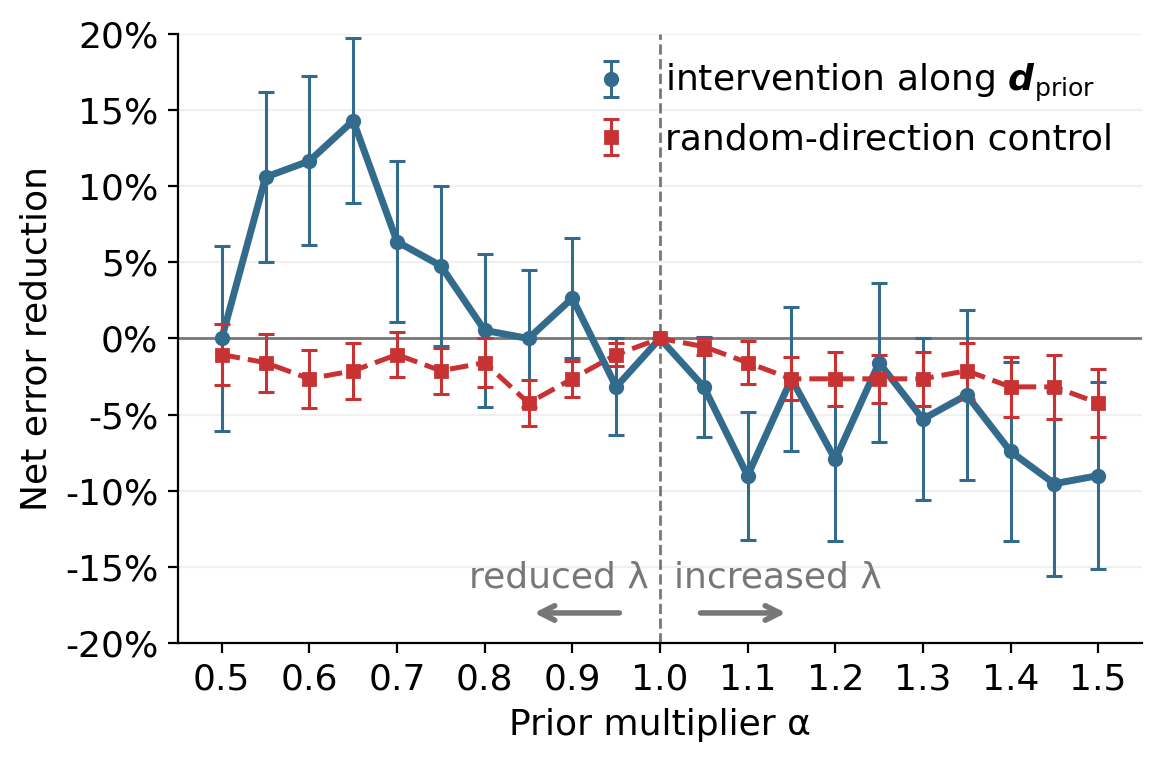

Net error reduction: (corrected − broken) / baseline errors.
Whiskers: ±1 SE of the paired per-problem change d_i ∈ {+1, 0, −1} (Wald / plug-in variance), scaled by n / baseline errors.
GSM8K training calibration subset (n=1,536); 8-shot CoT; greedy decoding (T=0).
Exploratory; post-hoc scoring/subset choice; no selection adjustment.
Matched 1,536-example questions/prompts; separate runtime baseline; one random seed, not norm-matched.


In [62]:
def wald_error_reduction(row):
    n = row["n"]
    dbar = row["difference"]
    wrong = n - row["baseline_correct"]
    scale = n / wrong
    se_acc = np.sqrt(max((row["corrected"] + row["broken"]) / n - dbar**2, 0) / n)
    return scale * dbar, scale * se_acc

arrow_offset = -0.6

fig, ax = plt.subplots(figsize=STYLE["figsize"], dpi=STYLE["dpi"])
guide_color = "#777777"
ax.axhline(0, color=guide_color, lw=1)
ax.axvline(1, color=guide_color, ls="--", lw=1)
endpoints = []
data_lo, data_hi = STYLE["data_xlim"]
def curve(rows, color, label, linewidth, marker="o", linestyle="-"):
    lookup = {round(r["alpha"],2): r for r in rows}
    grid = np.arange(round(data_lo * 20), round(data_hi * 20) + 1) / 20
    ax.plot(grid, [100*wald_error_reduction(lookup[round(a,2)])[0] if round(a,2) in lookup else np.nan for a in grid],
            color=color, lw=linewidth, ls=linestyle, zorder=3)
    shown = [r for r in rows if data_lo <= r["alpha"] <= data_hi]
    x = np.array([r["alpha"] for r in shown])
    y = 100*np.array([wald_error_reduction(r)[0] for r in shown])
    se = 100*np.array([wald_error_reduction(r)[1] for r in shown])
    endpoints.extend(np.concatenate([y - se, y + se]))
    ax.errorbar(x, y, yerr=se if STYLE["show_whiskers"] else None,
        fmt=marker,color=color,ms=STYLE["marker_size"],elinewidth=STYLE["whisker_width"],
        capsize=STYLE["cap_size"],capthick=STYLE["whisker_width"],label=label,zorder=4)

curve(blue, STYLE["blue"], "intervention along " + r"$\boldsymbol{d}_{\mathrm{prior}}$", STYLE["blue_linewidth"])
curve(red, STYLE["red"], control_label, STYLE["red_linewidth"], marker="s", linestyle="--")
ax.set_xlim(*STYLE["xlim"])
ax.set_ylim(-20, 20)
lo, hi = ax.get_xlim()
ax.set_xlabel("Prior multiplier α", fontsize=STYLE["xlabel_font"])
ax.set_ylabel("Net error reduction", fontsize=STYLE["ylabel_font"])
ax.set_xticks(np.arange(np.ceil(lo * 10 - 1e-9), np.floor(hi * 10 + 1e-9) + 1) / 10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))
if STYLE["show_region_labels"]:
    trans = ax.get_xaxis_transform()
    arrow = dict(arrowstyle="->", color=guide_color, lw=2)
    ax.text(0.885, 0.68+arrow_offset, "reduced λ", transform=trans, ha="center", va="bottom",
            color=guide_color, fontsize=STYLE["region_font"])
    ax.annotate("", xy=(0.85, 0.65+arrow_offset), xytext=(0.96, 0.65+arrow_offset),
                xycoords=trans, textcoords=trans, arrowprops=arrow)
    ax.text(1.135, 0.68+arrow_offset, "increased λ", transform=trans, ha="center", va="bottom",
            color=guide_color, fontsize=STYLE["region_font"])
    ax.annotate("", xy=(1.15, 0.65+arrow_offset), xytext=(1.04, 0.65+arrow_offset),
                xycoords=trans, textcoords=trans, arrowprops=arrow)
if STYLE["show_title"]:
    ax.set_title("Llama-3.2-3B-Instruct: exploratory prior calibration", fontsize=STYLE["title_font"], pad=18)
ax.legend(loc="upper right", ncol=1, frameon=False, fontsize=STYLE["legend_font"],
          borderaxespad=0.4, handletextpad=0.5, columnspacing=1.4)
ax.grid(axis="y", alpha=.18, visible=STYLE["show_grid"])
ax.spines[["top","right"]].set_visible(False)
caption = ("Net error reduction: (corrected − broken) / baseline errors.\n"
           "Whiskers: ±1 SE of the paired per-problem change d_i ∈ {+1, 0, −1} "
           "(Wald / plug-in variance), scaled by n / baseline errors.\n"
           "GSM8K training calibration subset (n=1,536); 8-shot CoT; greedy decoding (T=0).\n"
           "Exploratory; post-hoc scoring/subset choice; no selection adjustment.\n" + status_note)
fig.tight_layout()
if EXPORT:
    suffix = "" if matched else "_provisional"
    for ext in ["png", "pdf"]:
        fig.savefig(OUT / f"fig4_2_alpha_sweep_wald_se{suffix}.{ext}",
                    dpi=STYLE["dpi"], bbox_inches="tight", pad_inches=.15)
plt.show()
if STYLE["show_caption"]:
    print(caption)

In [57]:
from IPython.display import display, Markdown

figure_link = "[View generated Figure 4.2 (PDF)](../prior_calibration/plot_export/fig4_2_alpha_sweep_wald_se.pdf)"
display(Markdown(figure_link))

[View generated Figure 4.2 (PDF)](../prior_calibration/plot_export/fig4_2_alpha_sweep_wald_se.pdf)

## Draft: new Figure~4 caption + Section~5 prose

Yes — the current manuscript is at `paper_latex/iclr2026/direction_of_ignorance.tex`.
Section~\ref{sec:intervention} (``Intervening on $\lambda$…'') and Figure~\ref{fig:lambda-intervention} are the WikiText KL-steering result. Below is a drop-in draft that replaces that figure and its surrounding section with the matched GSM8K error-reduction experiment (Wald-SE panel; `fig4_2_alpha_sweep_wald_se.pdf`).

**Also update contribution bullet~(4) in the Introduction** so it matches the new claim, e.g.:
> Intervening on $\lambda$ along $\boldsymbol{d}_{\mathrm{prior}}$ changes GSM8K accuracy, while a matched random-direction control does not.

---

### Suggested section title

```latex
\section{Intervening on \texorpdfstring{$\lambda$}{lambda} Improves Mathematical Reasoning}
\label{sec:intervention}
```

---

### Caption (for `\caption{...}`)

```latex
\textbf{Reducing prior loading recovers GSM8K errors; amplifying it creates them.}
On a fixed GSM8K training calibration subset ($n{=}1{,}536$), we intervene on
\texttt{Llama-3.2-3B-Instruct} during greedy 8-shot chain-of-thought decoding by
rescaling the projection of the final pre-unembedding state onto
$\boldsymbol{d}_{\mathrm{prior}}$
(Equation~\ref{eq:alpha-patch}).
The plotted value is remaining-error reduction,
$(\mathrm{corrected}-\mathrm{broken})/\mathrm{baseline\ errors}$,
relative to the unmodified model ($\alpha{=}1$).
Blue: intervention along the fitted prior direction.
Red: matched random-direction control on the same questions and prompts.
Whiskers are $\pm 1$ standard error of the paired per-problem change
$d_i\in\{+1,0,-1\}$ (Wald / plug-in variance), scaled by
$n$ over baseline errors.
At $\alpha{=}0.65$ the fitted arm recovers $14.3\%$ of remaining errors
($66$ corrected, $39$ broken; $+1.76$ accuracy points on an $87.7\%$ baseline);
the control stays near zero.
This sweep is exploratory: the subset and presentation were chosen post hoc,
and intervals are not selection-adjusted.
```

---

### Surrounding section text

```latex
The prior loading factor is not merely a correlate of contextual uncertainty.
If $\boldsymbol{d}_{\mathrm{prior}}$ is causally active, intervening on its
loading should change not only geometric proximity to the unigram prior, but
also downstream task behavior.
We test this on mathematical reasoning with \texttt{Llama-3.2-3B-Instruct}.

\paragraph{Setup.}
We evaluate greedy 8-shot chain-of-thought decoding on a fixed GSM8K training
calibration subset of $n{=}1{,}536$ problems.
At every generated token we replace the final pre-unembedding activation
$\boldsymbol{y}$ by a rescaled projection onto the fitted prior direction,
\begin{equation}
    \boldsymbol{y}(\alpha)
    :=
    \boldsymbol{y}
    +
    (\alpha-1)\,
    \bigl(\boldsymbol{y}\!\cdot\!\boldsymbol{d}_{\mathrm{prior}}\bigr)\,
    \boldsymbol{d}_{\mathrm{prior}},
    \label{eq:alpha-patch}
\end{equation}
which multiplies the instantaneous prior loading by the scalar $\alpha$ while
leaving the orthogonal residual unchanged.
Thus $\alpha{<}1$ reduces prior loading, $\alpha{=}1$ is a no-op, and
$\alpha{>}1$ amplifies it.
As a specificity control we repeat the same protocol along one fixed random
unit direction, using the identical questions, prompts, and decoding settings.

\paragraph{Metric.}
Because the unmodified model already solves $87.7\%$ of this subset, raw
accuracy gains are small by construction.
We therefore report \emph{remaining-error reduction}
\[
    \frac{\#\{\text{wrong}\!\to\!\text{right}\}
          -\#\{\text{right}\!\to\!\text{wrong}\}}
         {\#\{\text{baseline wrong}\}},
\]
i.e.\ net accuracy change expressed as a fraction of the problems the
baseline still misses.
Whiskers are $\pm 1$ paired Wald standard error of the per-problem change
$d_i\in\{+1,0,-1\}$.

\begin{figure}[t]
    \centering
    \includegraphics[width=0.92\linewidth]{figures/fig4_2_alpha_sweep_wald_se.pdf}
    \caption{
    % paste caption from above
    }
    \label{fig:lambda-intervention}
\end{figure}

\paragraph{Results.}
Figure~\ref{fig:lambda-intervention} shows a clear, direction-specific effect.
Reducing prior loading along $\boldsymbol{d}_{\mathrm{prior}}$ recovers errors
over a contiguous band of $\alpha{<}1$, peaking at $\alpha{=}0.65$ with a
$14.3\%$ reduction of remaining errors
($66$ corrected versus $39$ newly broken; $+1.76$ accuracy points).
Amplifying the same direction ($\alpha{>}1$) moves the curve below zero:
the model breaks more problems than it fixes.
The matched random-direction control remains near flat across the displayed
range, so the gains are not explained by a generic perturbation of
comparable magnitude at the language-model head.
Together with the geometric results of Sections~\ref{sec:direction}
and~\ref{sec:dynamics}, this shows that $\boldsymbol{d}_{\mathrm{prior}}$ is
not only a statistical correlate of the unigram prior, but a causally active
control knob for how much the model relies on it during reasoning.
```

---

### Notes for integration

1. Copy `prior_calibration/plot_export/fig4_2_alpha_sweep_wald_se.pdf` into `paper_latex/iclr2026/figures/` (or update the `\includegraphics` path).
2. The old WikiText KL panel can move to the appendix if you still want the geometric steering evidence; otherwise contribution bullet~(4) should be retuned as above.
3. Tone matches the rest of the paper: claim is causal *for this intervention*, but the sweep/subset are flagged as exploratory.


In [58]:
f"fig4_2_alpha_sweep_wald_se{suffix}.{ext}"

'fig4_2_alpha_sweep_wald_se.pdf'

## Paper caption draft

**Exploratory prior calibration on GSM8K (1 SE).** Error reduction relative to the unmodified model (α=1) for Llama-3.2-3B-Instruct under greedy 8-shot CoT decoding. The plotted value is (corrected − broken) / baseline errors. Blue varies loading along the fitted prior direction; red varies loading along one fixed random direction. Whiskers are ±1 standard error of the paired per-problem change \(d_i\in\{+1,0,-1\}\) (Wald / plug-in variance of \(d_i\)), expressed as a share of remaining errors. This is the usual 1σ bar for a paired difference of proportions, not a 90% bootstrap interval. The subset and presentation were selected after inspection; intervals are not selection-adjusted. Red is the matched 1,536-example random-direction control on the same prompts.


## Generation length

Does the intervention change *how much* the model writes, not just whether it is right? Statistics come from `prior_calibration/token_length_sweep.py`, which writes `data/token_length_1536_sweep.json`.

Length is the number of generated tokens, recovered by re-encoding each saved response with the model's own tokenizer (`add_special_tokens=False`). The fitted arm also records `generated_tokens` at decode time; re-encoding reproduces it exactly on all 1,536 × 23 fitted generations, so both arms are measured the same way even though the control never logged the field. Greedy decoding with `max_gen_toks=1024`; truncation hits 2–6 of 1,536 per arm (≲0.4%), so the cap does not drive the means.

Two panels, because the two questions need different error bars:

- **Absolute mean length** with ±1 SE *across problems*. Those whiskers are wide (~1.5 tokens) because GSM8K problems genuinely differ in length; they describe the spread of the mean, not the α contrast.
- **Paired change versus α = 1** with ±1 SE of the per-problem difference. Every α reuses the same 1,536 prompts, so this is the panel that carries the inference.

Coverage differs: the fitted sweep runs α ∈ [0.10, 1.20], the matched control α ∈ [0.50, 1.25]. The axis spans both and each series is drawn only where it has data.

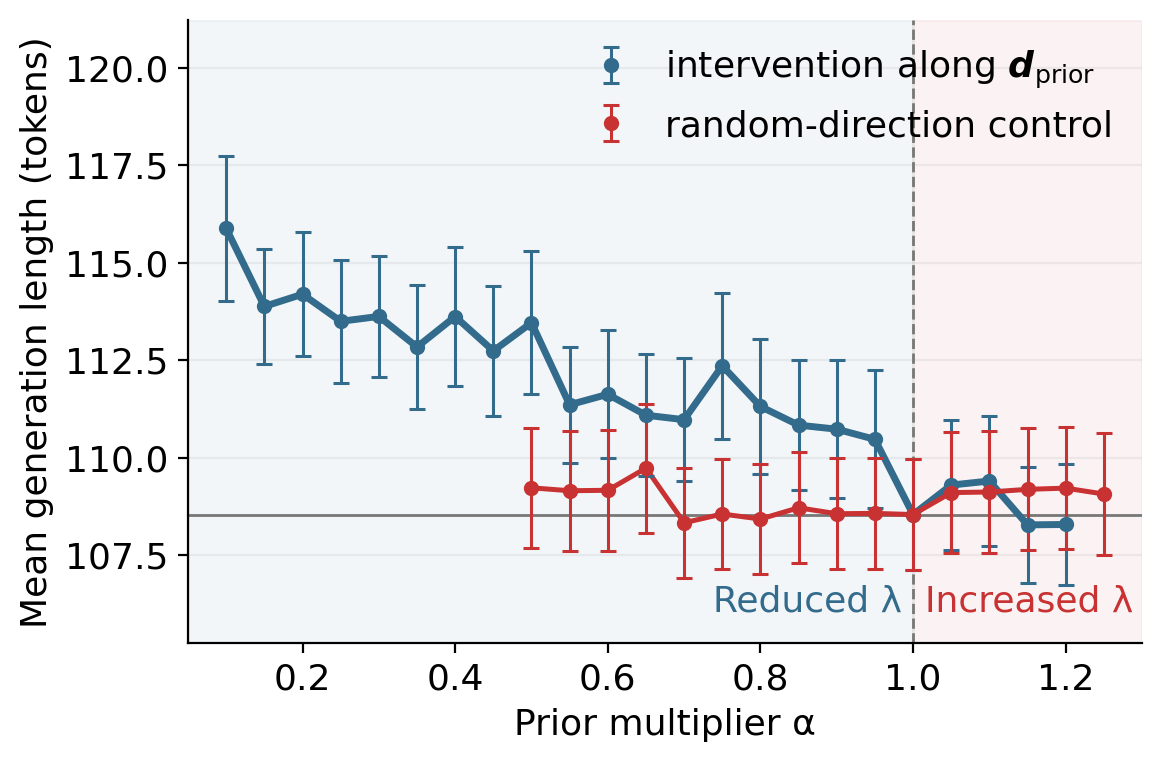

Mean generated tokens per problem, GSM8K training calibration subset (n=1,536);
8-shot CoT; greedy decoding (T=0); max_gen_toks=1024.
Whiskers: ±1 SE of the mean across problems. Problem-to-problem length variation
dominates this SE; the paired α contrast is in the next panel.
Unmodified model (α=1): 108.54 tokens, identical in both arms.
Matched 1,536-example questions/prompts; separate runtime baseline; one random seed, not norm-matched.


In [59]:
LEN = json.loads((DATA / "token_length_1536_sweep.json").read_text())
blue_len, red_len = LEN["fitted"], LEN["random"]
assert all(r["n"] == 1536 for r in blue_len + red_len)
assert all(r["recorded_mismatch"] in (0, None) for r in blue_len + red_len), "re-encoded length disagrees with the logged generated_tokens"
anchor = {name: next(r for r in rows if r["alpha"] == 1.)["mean_tokens"]
          for name, rows in [("fitted", blue_len), ("random", red_len)]}
assert abs(anchor["fitted"] - anchor["random"]) < 1e-9, "alpha=1 is a no-op, so both arms must give identical lengths"

# Wider axis than the accuracy panels: the fitted sweep reaches alpha=0.1.
S = dict(STYLE, xlim=(0.05, 1.3), data_xlim=(0.1, 1.25), xtick_step=0.2)

def draw_length(value, error, ylabel, filename, ypad=(1.5, 3.5), legend_loc="upper right"):
    fig, ax = plt.subplots(figsize=S["figsize"], dpi=S["dpi"])
    ax.axhline(value(next(r for r in blue_len if r["alpha"] == 1.)), color="#777777", lw=1)
    ax.axvline(1, color="#777777", ls="--", lw=1)
    endpoints = []
    data_lo, data_hi = S["data_xlim"]

    def curve(rows, color, label, linewidth):
        lookup = {round(r["alpha"], 2): r for r in rows}
        grid = np.arange(round(data_lo * 20), round(data_hi * 20) + 1) / 20
        ax.plot(grid, [value(lookup[round(a, 2)]) if round(a, 2) in lookup else np.nan for a in grid],
                color=color, lw=linewidth, zorder=3)
        shown = [r for r in rows if data_lo <= r["alpha"] <= data_hi]
        x = np.array([r["alpha"] for r in shown])
        y = np.array([value(r) for r in shown])
        se = np.array([error(r) for r in shown])
        endpoints.extend(np.concatenate([y - se, y + se]))
        ax.errorbar(x, y, yerr=se if S["show_whiskers"] else None,
            fmt="o", color=color, ms=S["marker_size"], elinewidth=S["whisker_width"],
            capsize=S["cap_size"], capthick=S["whisker_width"], label=label, zorder=4)

    curve(blue_len, S["blue"], "intervention along " + r"$\boldsymbol{d}_{\mathrm{prior}}$", S["blue_linewidth"])
    curve(red_len, S["red"], control_label, S["red_linewidth"])
    ax.set_xlim(*S["xlim"])
    ax.set_ylim(min(endpoints) - ypad[0], max(endpoints) + ypad[1])
    lo, hi = ax.get_xlim()
    if lo < 1:
        ax.axvspan(lo, min(1, hi), color=S["blue"], alpha=S["shade_alpha"], zorder=0)
    if hi > 1:
        ax.axvspan(max(1, lo), hi, color=S["red"], alpha=S["shade_alpha"], zorder=0)
    ax.set_xlabel("Prior multiplier α", fontsize=S["xlabel_font"])
    ax.set_ylabel(ylabel, fontsize=S["ylabel_font"])
    step = S["xtick_step"]
    ax.set_xticks(np.round(np.arange(np.ceil(lo / step - 1e-9), np.floor(hi / step + 1e-9) + 1) * step, 2))
    if S["show_region_labels"]:
        trans = ax.get_xaxis_transform()
        ax.text(0.985, 0.04, "Reduced λ", transform=trans, ha="right", va="bottom",
                color=S["blue"], fontsize=S["region_font"])
        ax.text(1.015, 0.04, "Increased λ", transform=trans, ha="left", va="bottom",
                color=S["red"], fontsize=S["region_font"])
    ax.legend(loc=legend_loc, ncol=1, frameon=False, fontsize=S["legend_font"],
              borderaxespad=0.4, handletextpad=0.5, columnspacing=1.4)
    ax.grid(axis="y", alpha=.18, visible=S["show_grid"])
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    if EXPORT:
        suffix = "" if matched else "_provisional"
        for ext in ["png", "pdf"]:
            fig.savefig(OUT / f"{filename}{suffix}.{ext}", dpi=S["dpi"], bbox_inches="tight", pad_inches=.15)
    plt.show()

draw_length(lambda r: r["mean_tokens"], lambda r: r["se_tokens"],
            "Mean generation length (tokens)", "fig4_3_generation_length")

caption = ("Mean generated tokens per problem, GSM8K training calibration subset (n=1,536);\n"
           "8-shot CoT; greedy decoding (T=0); max_gen_toks=1024.\n"
           "Whiskers: ±1 SE of the mean across problems. Problem-to-problem length variation\n"
           "dominates this SE; the paired α contrast is in the next panel.\n"
           f"Unmodified model (α=1): {anchor['fitted']:.2f} tokens, identical in both arms.\n"
           + status_note)
if STYLE["show_caption"]:
    print(caption)

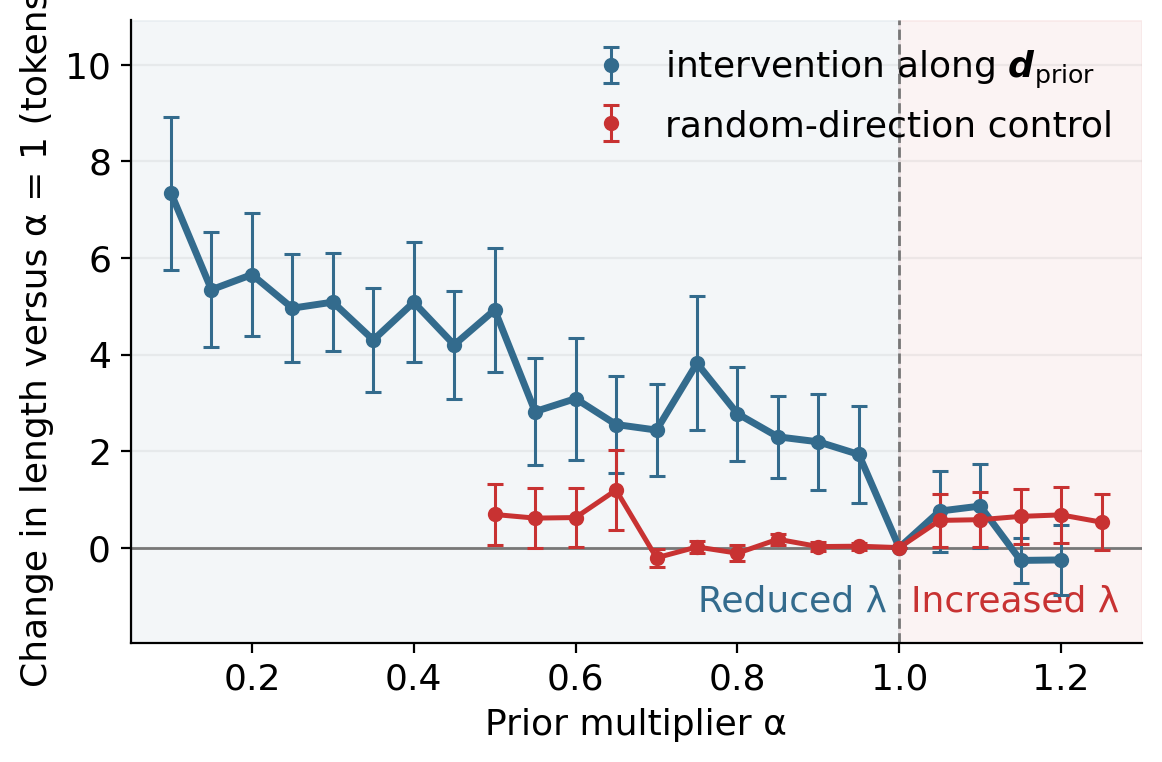

 alpha     fitted Δ      z      control Δ      z
   0.1        +7.34   4.63              —      —
  0.15        +5.34   4.46              —      —
   0.2        +5.66   4.43              —      —
  0.25        +4.96   4.43              —      —
   0.3        +5.09   5.00              —      —
  0.35        +4.30   3.97              —      —
   0.4        +5.08   4.10              —      —
  0.45        +4.20   3.77              —      —
   0.5        +4.92   3.82          +0.69   1.10
  0.55        +2.82   2.54          +0.61   0.98
   0.6        +3.09   2.44          +0.62   1.01
  0.65        +2.55   2.56          +1.19   1.45
   0.7        +2.43   2.54          -0.21  -1.11
  0.75        +3.82   2.75          +0.01   0.12
   0.8        +2.77   2.86          -0.12  -0.71
  0.85        +2.29   2.72          +0.17   1.51
   0.9        +2.19   2.19          +0.02   0.25
  0.95        +1.93   1.92          +0.03   0.40
   1.0        +0.00   0.00          +0.00   0.00
  1.05        +0.76 

In [60]:
draw_length(lambda r: r["paired_difference"], lambda r: r["paired_se"],
            "Change in length versus α = 1 (tokens)", "fig4_3_generation_length_delta",
            ypad=(1.0, 2.0), legend_loc="upper right")

print(f"{'alpha':>6} {'fitted Δ':>12} {'z':>6}   {'control Δ':>12} {'z':>6}")
for a in sorted({r["alpha"] for r in blue_len} | {r["alpha"] for r in red_len}):
    cells = []
    for rows in [blue_len, red_len]:
        row = next((r for r in rows if r["alpha"] == a), None)
        if row is None:
            cells.append(f"{'—':>12} {'—':>6}")
        else:
            z = row["paired_difference"] / row["paired_se"] if row["paired_se"] else 0.
            cells.append(f"{row['paired_difference']:>+12.2f} {z:>6.2f}")
    print(f"{a:>6} {cells[0]}   {cells[1]}")

caption = ("Paired change in generated tokens relative to the unmodified model (α=1), same\n"
           "1,536 problems at every α. Whiskers: ±1 SE of the per-problem difference.\n"
           "Reducing loading along the fitted prior direction lengthens generations\n"
           "progressively; the matched random direction is flat in both directions.\n"
           "Exploratory; post-hoc scoring/subset choice; no selection adjustment.\n"
           + status_note)
if STYLE["show_caption"]:
    print("\n" + caption)

### What the length sweep shows

The unmodified model averages **108.54 tokens**, and both arms reproduce that number exactly at α = 1 — a useful end-to-end check that the intervention is a true no-op there.

Down-weighting the fitted prior direction makes the model **write more**, and the effect grows as α falls: +1.9 tokens at α = 0.95, +2.8 at α = 0.55, +4.9 at α = 0.50, +7.3 at α = 0.10 (≈ +6.8% of baseline length). Every α ≤ 0.9 sits at |z| ≥ 2.2 on the paired difference, and everything below α = 0.5 is z ≈ 4–5. Above α = 1 the curve is flat to slightly negative, so the effect is one-sided.

The matched random direction is **flat**: every point lies within ±1.2 tokens of baseline and all 15 alphas have |z| < 1.6. So the lengthening is specific to the fitted direction, not a generic consequence of perturbing the `lm_head` input by a vector of comparable size.

Read alongside the error-reduction panels, the same α region that recovers errors is the region that produces longer chains of thought — consistent with reduced prior loading letting the model deliberate instead of committing early. This is correlational at the sweep level; it does not establish that the extra tokens *cause* the accuracy gain. A per-problem decomposition (length change on corrected vs. broken vs. unchanged items) would be the natural follow-up.

**Caveat on the whiskers.** The absolute panel's ±1 SE (~1.5 tokens) is dominated by genuine problem-to-problem length variation and makes the arms look overlapping; the paired panel removes that shared variance and is the correct comparison. Do not read the absolute panel as a null result.

**Caption draft.** *Generation length under prior calibration.* Mean generated tokens on the GSM8K training calibration subset (n = 1,536) for Llama-3.2-3B-Instruct, 8-shot CoT, greedy decoding, `max_gen_toks` = 1024. Blue varies loading along the fitted prior direction \(\boldsymbol{d}_{\mathrm{prior}}\); red varies loading along one fixed random direction on the same prompts. Whiskers are ±1 SE of the paired per-problem change relative to α = 1. Reducing prior loading lengthens generations by up to 7.3 tokens (+6.8%), while the random-direction control stays within ±1.2 tokens of baseline. Truncation at the token cap affects ≤ 6 of 1,536 generations per setting. Exploratory; the subset and presentation were chosen post hoc and intervals are not selection-adjusted; the control uses a single random seed and is not norm-matched.

## Does getting longer predict getting corrected?

The sweep shows that reducing prior loading both recovers errors and lengthens generations. If the extra tokens were the mechanism, then within the problems whose correctness *flips* at α = 0.65, the ones that got longer should be the ones that got fixed.

Statistics come from `prior_calibration/flip_length_analysis.py` (writes `data/flip_length_0p65.json`). Correctness is `unit_aware`, the metric behind the accuracy panels. At α = 0.65 the 1,536 problems split into 66 corrected (wrong→right), 39 broken (right→wrong), 1,308 stably correct and 123 stably wrong; the test is restricted to the 105 flipped items.

Left panel is the empirical CDF of the per-problem length change, on a symmetric-log axis so the two runaway generations stay visible. Right panel is the share corrected within quartiles of length change, with 95% Wilson intervals — if length predicted correction this line would slope up.

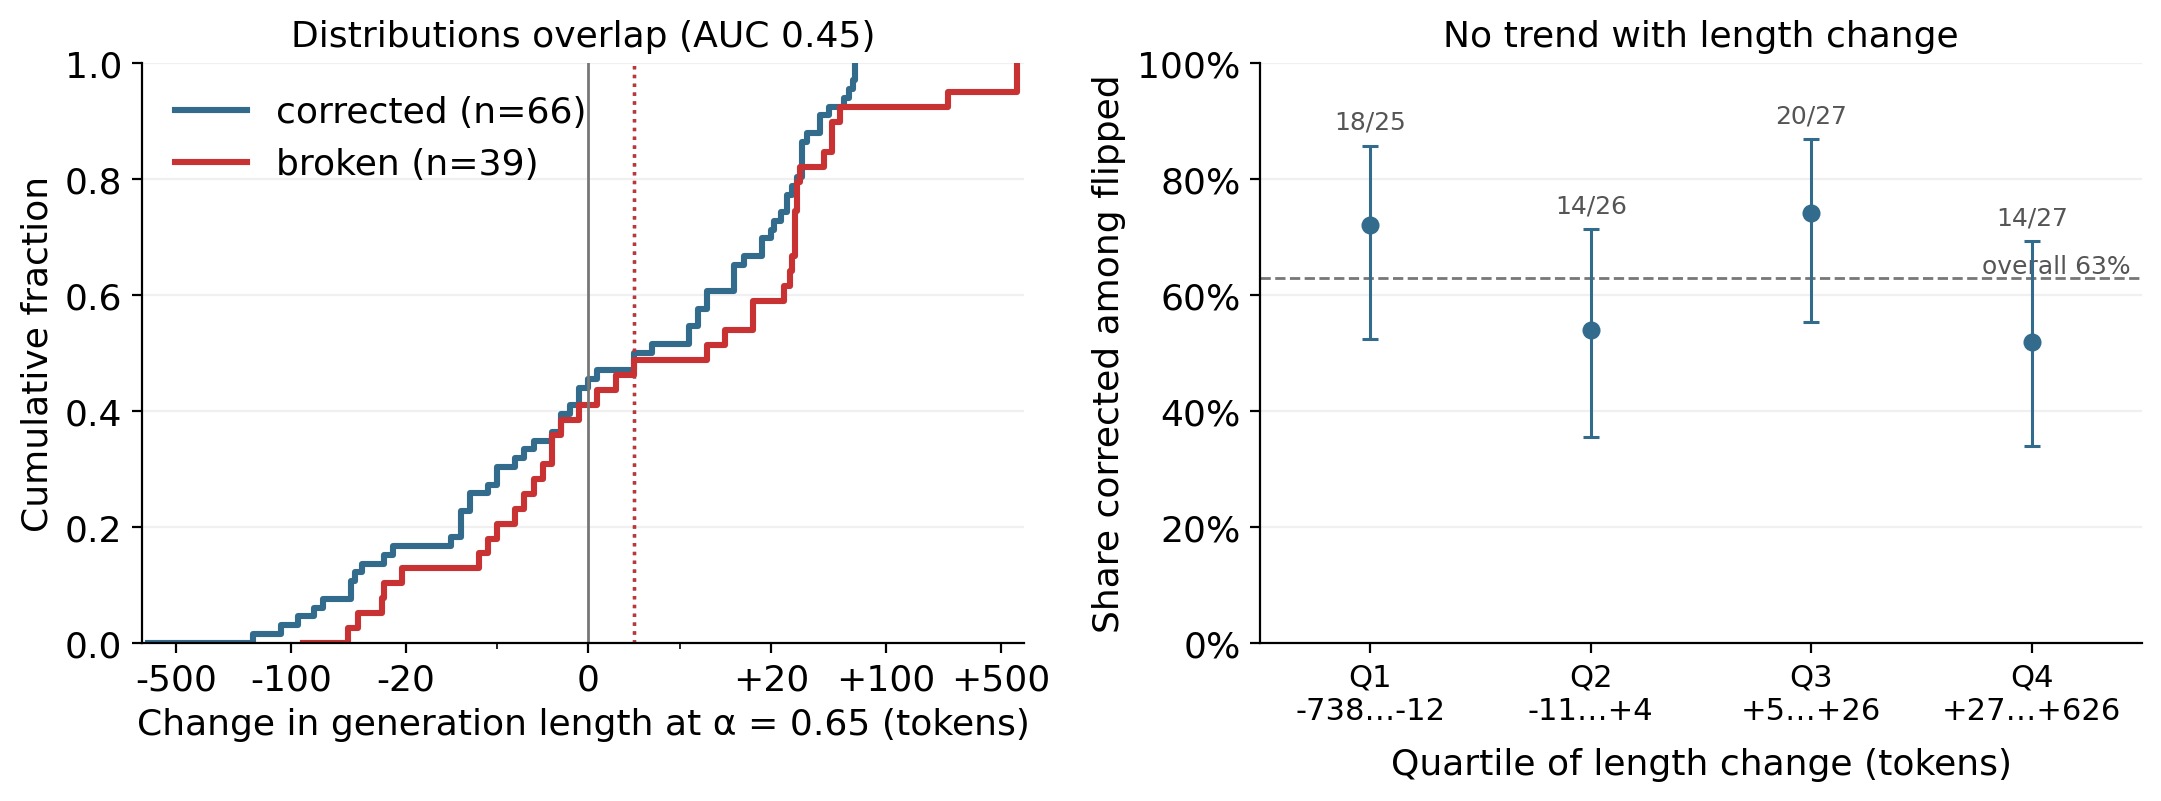

                sample     n  mean Δ corr  mean Δ brok    MW p    AUC  OR/+10tok       p
           all flipped   105       -10.97       +27.15   0.363  0.447      0.933   0.138
   excluding truncated   103        +0.22       +11.39   0.561  0.465      0.937   0.215
       winsorized 5/95   105        +1.31        +8.22   0.383  0.449      0.928   0.272

Flipped problems at α=0.65 on the fitted prior direction (unit-aware scoring):
66 corrected, 39 broken, of n=1,536.
Length change does not separate the two: identical medians (+5 tokens), AUC
0.45 [0.33, 0.56], Mann-Whitney p=0.36.
Raw means are driven by the two generations that hit the 1024-token cap;
the conclusion is unchanged after excluding or winsorizing them.
Exploratory; post-hoc subgroup; no selection adjustment.


In [61]:
FLIP = json.loads((DATA / "flip_length_0p65.json").read_text())
flip = FLIP["flipped"]
delta = {g: np.array([r["delta"] for r in FLIP["rows"] if r["group"] == g], dtype=float)
         for g in ["corrected", "broken"]}
assert len(delta["corrected"]) == flip["corrected"] and len(delta["broken"]) == flip["broken"]

def wilson(k, n, z=1.96):
    p, d = k / n, 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=STYLE["dpi"])

ax = axes[0]
for group, color, label in [("corrected", STYLE["blue"], f"corrected (n={flip['corrected']})"),
                            ("broken", STYLE["red"], f"broken (n={flip['broken']})")]:
    v = np.sort(delta[group])
    ax.step(np.concatenate([v, v[-1:]]), np.arange(len(v) + 1) / len(v),
            where="post", color=color, lw=2.2, label=label)
    ax.axvline(np.median(v), color=color, ls=":", lw=1.2)
ax.axvline(0, color="#777777", lw=1)
ax.set_xscale("symlog", linthresh=20)
ax.set_xticks([-500, -100, -20, 0, 20, 100, 500])
ax.get_xaxis().set_major_formatter(FuncFormatter(lambda v, _: f"{v:+g}" if v else "0"))
ax.set_xlabel("Change in generation length at α = 0.65 (tokens)", fontsize=STYLE["xlabel_font"])
ax.set_ylabel("Cumulative fraction", fontsize=STYLE["ylabel_font"])
ax.set_ylim(0, 1)
ax.legend(loc="upper left", frameon=False, fontsize=STYLE["legend_font"])
ax.set_title(f"Distributions overlap (AUC {flip['auc']:.2f})", fontsize=STYLE["title_font"])

ax = axes[1]
d_all = np.concatenate([delta["corrected"], delta["broken"]])
y_all = np.concatenate([np.ones(flip["corrected"]), np.zeros(flip["broken"])])
edges = np.percentile(d_all, [0, 25, 50, 75, 100])
edges[-1] += 1
base_rate = y_all.mean()
ax.axhline(100 * base_rate, color="#777777", ls="--", lw=1)
for i in range(4):
    sel = (d_all >= edges[i]) & (d_all < edges[i + 1])
    k, n = int(y_all[sel].sum()), int(sel.sum())
    lo, hi = wilson(k, n)
    x = np.median(d_all[sel])
    ax.errorbar([i], [100 * k / n], yerr=[[100 * (k / n - lo)], [100 * (hi - k / n)]],
                fmt="o", color=STYLE["blue"], ms=STYLE["marker_size"] + 1,
                elinewidth=STYLE["whisker_width"], capsize=STYLE["cap_size"],
                capthick=STYLE["whisker_width"], zorder=4)
    ax.annotate(f"{k}/{n}", (i, 100 * hi), textcoords="offset points", xytext=(0, 6),
                ha="center", fontsize=STYLE["note_font"] + 1, color="#555555")
ax.set_xticks(range(4))
ax.set_xticklabels([f"Q{i+1}\n{edges[i]:+.0f}…{edges[i+1]-1:+.0f}" for i in range(4)],
                   fontsize=STYLE["tick_font"] - 2)
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(0, 100)
ax.set_xlabel("Quartile of length change (tokens)", fontsize=STYLE["xlabel_font"], labelpad=8)
ax.set_ylabel("Share corrected among flipped", fontsize=STYLE["ylabel_font"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_title("No trend with length change", fontsize=STYLE["title_font"])
ax.annotate(f"overall {100*base_rate:.0f}%", (3.45, 100 * base_rate), ha="right", va="bottom",
            fontsize=STYLE["note_font"] + 1, color="#555555")

for ax in axes:
    ax.grid(axis="y", alpha=.18, visible=STYLE["show_grid"])
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
if EXPORT:
    for ext in ["png", "pdf"]:
        fig.savefig(OUT / f"fig4_4_flip_length_0p65.{ext}", dpi=STYLE["dpi"],
                    bbox_inches="tight", pad_inches=.15)
plt.show()

print(f"{'sample':>22} {'n':>5} {'mean Δ corr':>12} {'mean Δ brok':>12} {'MW p':>7} {'AUC':>6} {'OR/+10tok':>10} {'p':>7}")
for name, s in flip["sensitivity"].items():
    print(f"{name:>22} {s['n']:>5} {s['mean_delta_corrected']:>+12.2f} {s['mean_delta_broken']:>+12.2f} "
          f"{s['mannwhitney_p']:>7.3f} {s['auc']:>6.3f} "
          f"{s['logistic']['delta']['or_per_10_tokens']:>10.3f} {s['logistic']['delta']['p']:>7.3f}")

caption = ("Flipped problems at α=0.65 on the fitted prior direction (unit-aware scoring):\n"
           f"{flip['corrected']} corrected, {flip['broken']} broken, of n=1,536.\n"
           "Length change does not separate the two: identical medians (+5 tokens), AUC\n"
           f"{flip['auc']:.2f} [{flip['auc_ci'][0]:.2f}, {flip['auc_ci'][1]:.2f}], "
           f"Mann-Whitney p={flip['mannwhitney_p']:.2f}.\n"
           "Raw means are driven by the two generations that hit the 1024-token cap;\n"
           "the conclusion is unchanged after excluding or winsorizing them.\n"
           "Exploratory; post-hoc subgroup; no selection adjustment.")
if STYLE["show_caption"]:
    print("\n" + caption)